In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv
load_dotenv()

/Users/sagarrudagi/Desktop/Learning/Coding - Projects/NLP Learning/lcm/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
/Users/sagarrudagi/Desktop/Learning/Coding - Projects/NLP Learning/lcm/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [10]:
model = ChatOpenAI(model="gpt-4o-mini")

In [3]:
# Create State
class LLMState(TypedDict):
    prompt: str
    response: str

In [12]:
def llm_prompt(state: LLMState) -> LLMState:
    question = state["prompt"]
    prompt = f"Answer the following question: {question}"
    state["response"] = model.invoke(prompt).content
    return state

In [7]:
# Define the graph
graph = StateGraph(LLMState)

# Add nodes
graph.add_node("llm_prompt", llm_prompt)

# Add edges
graph.add_edge(START, "llm_prompt")
graph.add_edge("llm_prompt", END)

# Compile the graph
workflow = graph.compile()

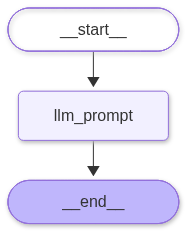

In [8]:
workflow

In [11]:
final_state = workflow.invoke({"prompt": "What is the capital of France?"})
print(final_state)

{'prompt': 'What is the capital of France?', 'response': 'The capital of France is Paris.'}
